In [1]:
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── Style ────────────────────────────────────────────────────────────────────

TEAL  = "#1D9E75"
BLUE  = "#378ADD"
CORAL = "#F0997B"
LGRAY = "#D3D1C7"
AMBER = "#EF9F27"
TEXT  = "#2C2C2A"
SGRAY = "#888780"

plt.rcParams.update({
    "font.family":        "sans-serif",
    "font.size":          11,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":     0.6,
    "xtick.major.size":   3,
    "ytick.major.size":   3,
    "figure.dpi":         150,
    "savefig.bbox":       "tight",
    "savefig.dpi":        150,
})

In [2]:
import os
os.chdir("/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index")


In [3]:
df = pd.read_csv("data/buildings_300m_indicator.csv")
df["within_300m"] = df["within_300m"].astype(str).str.strip().str.lower() == "true"
df["walk_dist_m"] = pd.to_numeric(df["walk_dist_m"], errors="coerce")
df["park_area_ha"] = pd.to_numeric(df["park_area_ha"], errors="coerce")

TOTAL = len(df)
N_WITHIN = df["within_300m"].sum()
CITY_AVG = N_WITHIN / TOTAL * 100

print(f"Loaded {TOTAL:,} addresses — {N_WITHIN:,} within 300m ({CITY_AVG:.1f}%)")


Loaded 77,630 addresses — 49,134 within 300m (63.3%)


In [4]:
# ── Euclidean distance (haversine, metres) ───────────────────────────────────
# Available for every row that has a matched entrance (within_300m == True).
# For fig3 we need it for all addresses; for rows without an entrance we use
# the nearest-park centroid approach — but here we only have the entrance
# coords, so we restrict the euclid comparison to matched rows only.

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6_371_000
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlam = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlam / 2) ** 2
    return R * 2 * np.arcsin(np.sqrt(a))

matched = df[df["within_300m"] & df["entrance_lat"].notna()].copy()
matched["euclid_dist_m"] = haversine_m(
    matched["latitude"].values,  matched["longitude"].values,
    matched["entrance_lat"].values, matched["entrance_lon"].values,
)
matched["ratio"] = matched["walk_dist_m"] / matched["euclid_dist_m"]

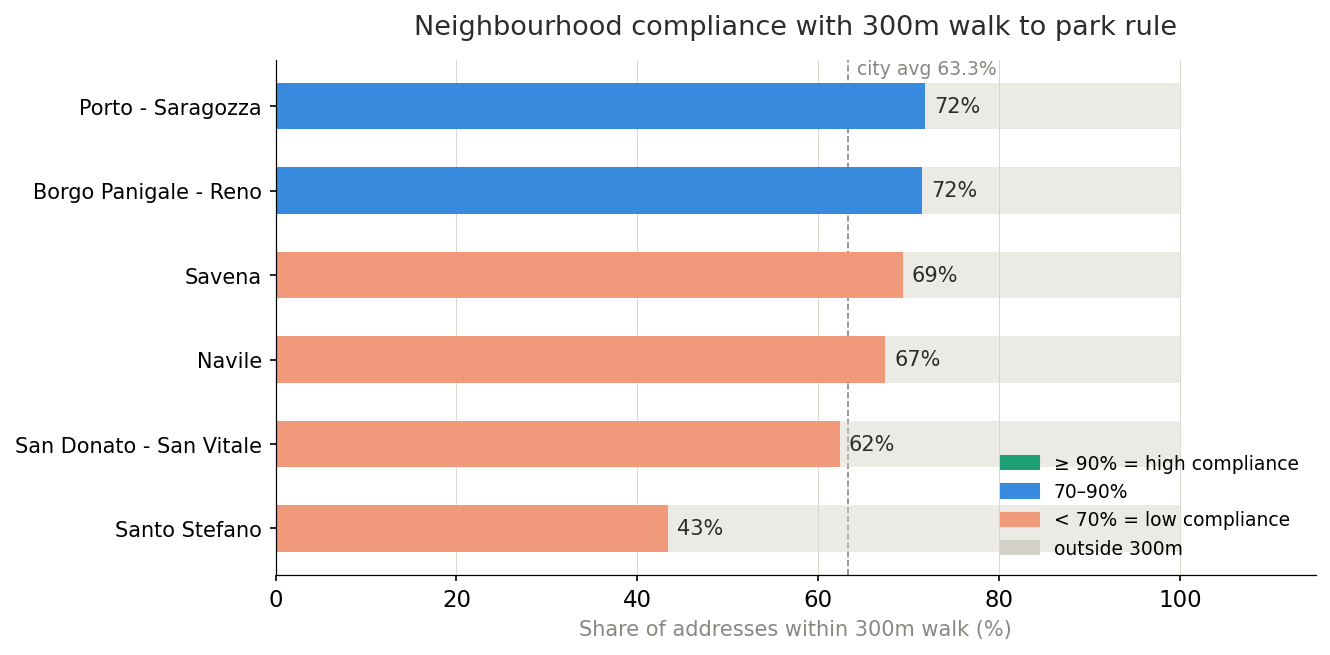

Saved fig1_neighbourhood_compliance.png


In [14]:

nb = (
    df.groupby("neighbourhood")["within_300m"]
    .agg(total="count", within="sum")
    .assign(pct=lambda x: x["within"] / x["total"] * 100)
    .sort_values("pct", ascending=True)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, max(4.5, len(nb) * 0.55)))

y     = np.arange(len(nb))
bar_h = 0.55
colors = [TEAL if p >= 90 else BLUE if p >= 70 else CORAL for p in nb.pct]

ax.barh(y, nb.pct,           height=bar_h, color=colors, zorder=2)
ax.barh(y, 100 - nb.pct,     height=bar_h, left=nb.pct,
        color=LGRAY, alpha=0.45, zorder=2)

for i, row in nb.iterrows():
    ax.text(row.pct + 1, i, f"{row.pct:.0f}%", va="center", fontsize=10, color=TEXT)
    if row.pct >= 99.5:
        ax.text(row.pct - 2, i, "✓", va="center", ha="right", fontsize=11,
                color="white", fontweight="bold")

ax.set_yticks(y)
ax.set_yticklabels(nb.neighbourhood, fontsize=10)
ax.set_xlabel("Share of addresses within 300m walk (%)", fontsize=10, color=SGRAY)
ax.set_xlim(0, 115)
ax.set_title("Neighbourhood compliance with 300m walk to park rule", fontsize=13,
             fontweight="500", pad=12, color=TEXT)
ax.axvline(CITY_AVG, color=SGRAY, linewidth=0.8, linestyle="--", zorder=1)
ax.text(CITY_AVG + 1, 5.55, f"city avg {CITY_AVG:.1f}%", fontsize=9, color=SGRAY, va="top")
ax.grid(axis="x", linewidth=0.4, color=LGRAY, zorder=0)

legend_els = [
    mpatches.Patch(color=TEAL,  label="≥ 90% = high compliance"),
    mpatches.Patch(color=BLUE,  label="70–90%"),
    mpatches.Patch(color=CORAL, label="< 70% = low compliance"),
    mpatches.Patch(color=LGRAY, label="outside 300m"),
]
ax.legend(handles=legend_els, loc="lower right", fontsize=9, frameon=False)

plt.tight_layout()
plt.show()
plt.savefig("fig1_neighbourhood_compliance.png")
plt.close()
print("Saved fig1_neighbourhood_compliance.png")



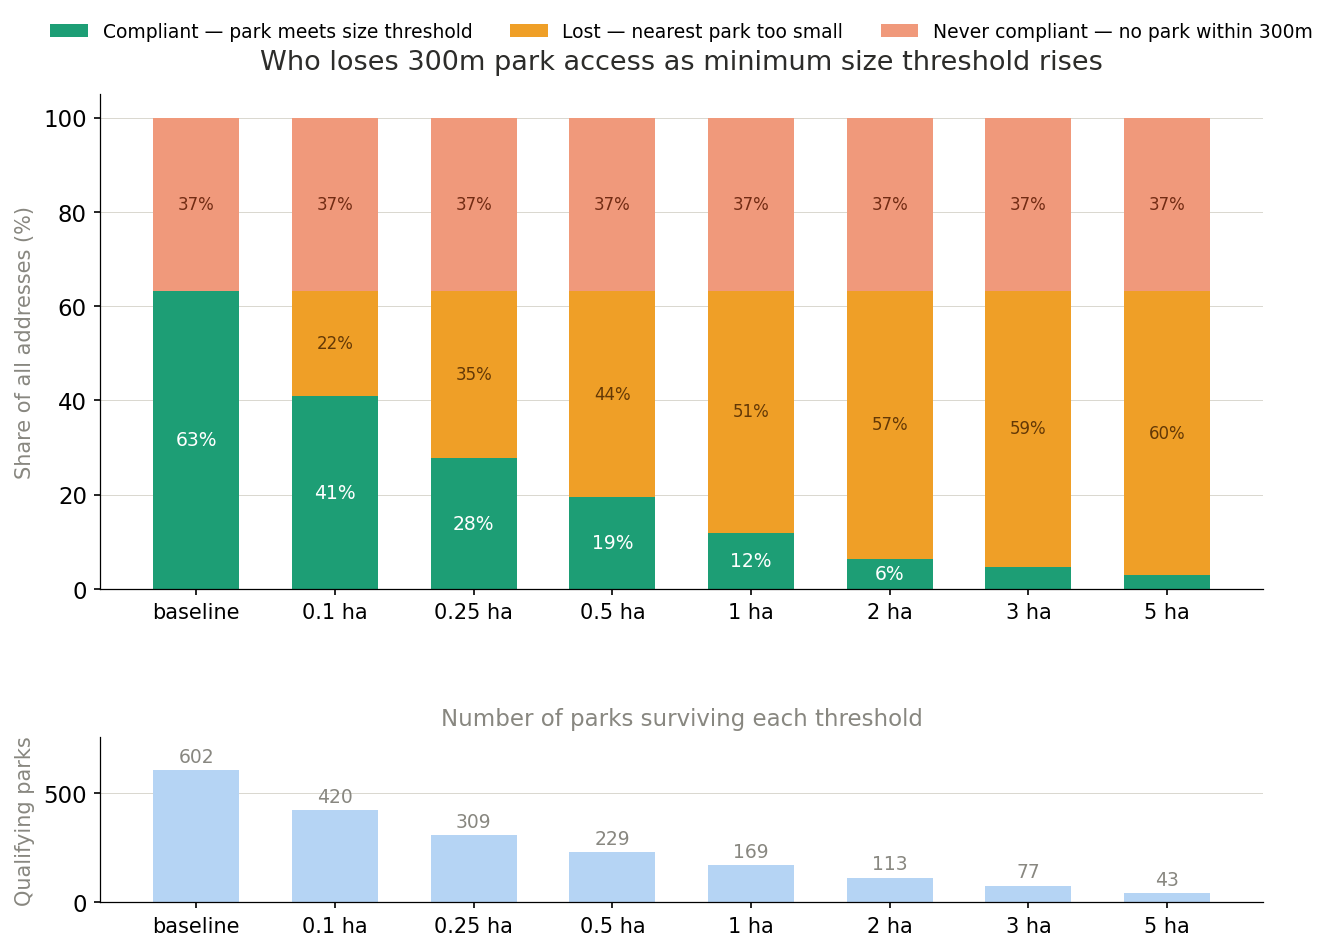

Saved fig2_park_size_filter.png


In [19]:

# ── Fig 2 · Park size threshold — who gets lost and why ──────────────────────
#
# Three address groups at each threshold:
#   compliant  — within 300m of a park that meets the size requirement
#   lost       — within 300m but their nearest park is smaller than threshold
#   never      — never within 300m regardless of size (no park reachable)
#
# "lost" is computed as: was within 300m at baseline, but the matched park
# is smaller than t ha.  It accumulates as threshold rises.

NEVER_N   = (~df["within_300m"]).sum()          # baseline non-compliant (fixed)
BASELINE  = df["within_300m"].sum()             # baseline compliant

thresholds_ha = [0, 0.1, 0.25, 0.5, 1.0, 2.0, 3.0, 5.0]
xlabels       = ["baseline", "0.1 ha", "0.25 ha", "0.5 ha", "1 ha", "2 ha", "3 ha", "5 ha"]

size_results = []
for t in thresholds_ha:
    if t == 0:
        compliant_n = BASELINE
    else:
        # compliant at threshold t = was within 300m AND park >= t ha
        compliant_n = df[df["within_300m"] & (df["park_area_ha"] >= t)].shape[0]
    lost_n  = BASELINE - compliant_n          # had access, lost it due to size
    n_parks = (df["nearest_park_id"]
               .loc[df["park_area_ha"] >= t]
               .nunique()) if t > 0 else df["nearest_park_id"].nunique()
    size_results.append({
        "threshold": t,
        "compliant": compliant_n,
        "lost":      lost_n,
        "never":     NEVER_N,
        "parks":     n_parks,
    })

size_df = pd.DataFrame(size_results)
size_df["c_pct"] = size_df["compliant"] / TOTAL * 100
size_df["l_pct"] = size_df["lost"]      / TOTAL * 100
size_df["n_pct"] = size_df["never"]     / TOTAL * 100

x     = np.arange(len(thresholds_ha))
width = 0.62

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10, 7),
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.45},
)

# ── Stacked bars ──
b1 = ax_top.bar(x, size_df.c_pct, width, color=TEAL,  label="Compliant — park meets size threshold",  zorder=2)
b2 = ax_top.bar(x, size_df.l_pct, width, bottom=size_df.c_pct, color=AMBER, label="Lost — nearest park too small", zorder=2)
b3 = ax_top.bar(x, size_df.n_pct, width, bottom=size_df.c_pct + size_df.l_pct, color=CORAL, label="Never compliant — no park within 300m", zorder=2)

# Percentage labels inside compliant segment (only where wide enough)
for i, row in size_df.iterrows():
    if row.c_pct > 5:
        ax_top.text(i, row.c_pct / 2, f"{row.c_pct:.0f}%",
                    ha="center", va="center", fontsize=9,
                    color="white", fontweight="500")
    if row.l_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct / 2, f"{row.l_pct:.0f}%",
                    ha="center", va="center", fontsize=8,
                    color="#633806")
    if row.n_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct + row.n_pct / 2, f"{row.n_pct:.0f}%",
                    ha="center", va="center", fontsize=8,
                    color="#712B13")

ax_top.set_xticks(x)
ax_top.set_xticklabels(xlabels, fontsize=10)
ax_top.set_ylabel("Share of all addresses (%)", fontsize=10, color=SGRAY)
ax_top.set_ylim(0, 105)
ax_top.set_title("Who loses 300m park access as minimum size threshold rises",
                 fontsize=13, fontweight="500", pad=12, color=TEXT)
ax_top.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)
ax_top.legend(fontsize=9, frameon=False, loc="upper center",
              bbox_to_anchor=(0.5, 1.18), ncol=3)

# ── Qualifying parks bar ──
ax_bot.bar(x, size_df.parks, width, color="#B5D4F4", zorder=2)
for i, row in size_df.iterrows():
    ax_bot.text(i, row.parks + size_df.parks.max() * 0.03,
                str(int(row.parks)), ha="center", va="bottom", fontsize=9, color=SGRAY)

ax_bot.set_xticks(x)
ax_bot.set_xticklabels(xlabels, fontsize=10)
ax_bot.set_ylabel("Qualifying parks", fontsize=10, color=SGRAY)
ax_bot.set_title("Number of parks surviving each threshold", fontsize=11,
                 fontweight="500", color=SGRAY, pad=6)
ax_bot.set_ylim(0, size_df.parks.max() * 1.25)
ax_bot.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

plt.show()
plt.savefig("fig2_park_size_filter.png")
plt.close()
print("Saved fig2_park_size_filter.png")



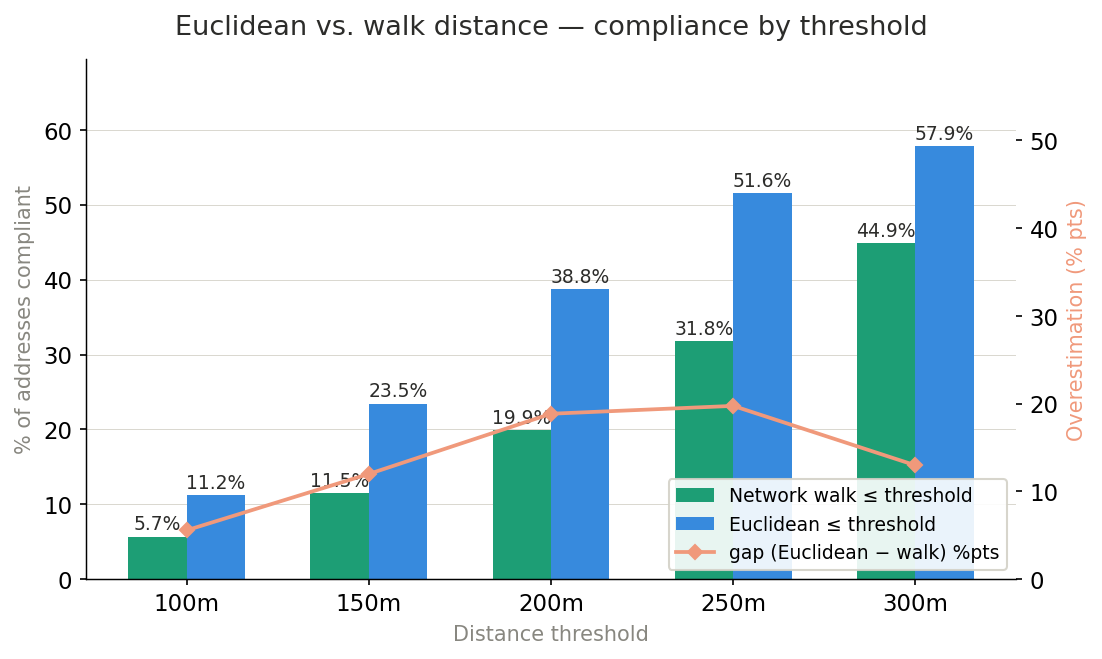

Saved fig3_euclid_vs_walk.png


In [27]:
# ── Fig 3 · Euclidean vs. walk compliance by threshold ───────────────────────
# Note: Euclidean is computed only for matched rows (entrance coords available).
# For unmatched rows, walk_dist_m is NaN → treated as non-compliant at all
# thresholds, which is correct.
 
dist_thresholds = [100, 150, 200, 250, 300]
 
walk_pct_real   = [(df["walk_dist_m"]          <= t).sum() / TOTAL * 100
                   for t in dist_thresholds]
euclid_pct_real = [(matched["euclid_dist_m"]   <= t).sum() / TOTAL * 100
                   for t in dist_thresholds]
false_pos       = [e - w for e, w in zip(euclid_pct_real, walk_pct_real)]
 
x = np.arange(len(dist_thresholds))
w = 0.32
 
fig, ax = plt.subplots(figsize=(8, 4.5))
 
b1 = ax.bar(x - w/2, walk_pct_real,   width=w, color=TEAL, label="Network walk ≤ threshold",
            zorder=2, linewidth=0)
b2 = ax.bar(x + w/2, euclid_pct_real, width=w, color=BLUE, label="Euclidean ≤ threshold",
            zorder=2, linewidth=0)
 
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
                f"{bar.get_height():.1f}%", ha="center", va="bottom", fontsize=9, color=TEXT)
 
ax.set_xticks(x)
ax.set_xticklabels([f"{t}m" for t in dist_thresholds])
ax.set_ylabel("% of addresses compliant", fontsize=10, color=SGRAY)
ax.set_xlabel("Distance threshold", fontsize=10, color=SGRAY)
ax.set_title("Euclidean vs. walk distance — compliance by threshold", fontsize=13,
             fontweight="500", pad=12, color=TEXT)
ax.set_ylim(0, max(euclid_pct_real) * 1.2)
ax.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)
 
ax2 = ax.twinx()
ax2.plot(x, false_pos, color=CORAL, linewidth=1.8, marker="D",
         markersize=5, label="gap (Euclidean − walk) %pts")
ax2.set_ylabel("Overestimation (% pts)", fontsize=10, color=CORAL)
ax2.set_ylim(0, max(false_pos) * 3)
 
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=9,
          frameon=True, framealpha=0.9, edgecolor=LGRAY)

plt.show()
plt.tight_layout()
plt.savefig("fig3_euclid_vs_walk.png")
plt.close()
print("Saved fig3_euclid_vs_walk.png")
 
 

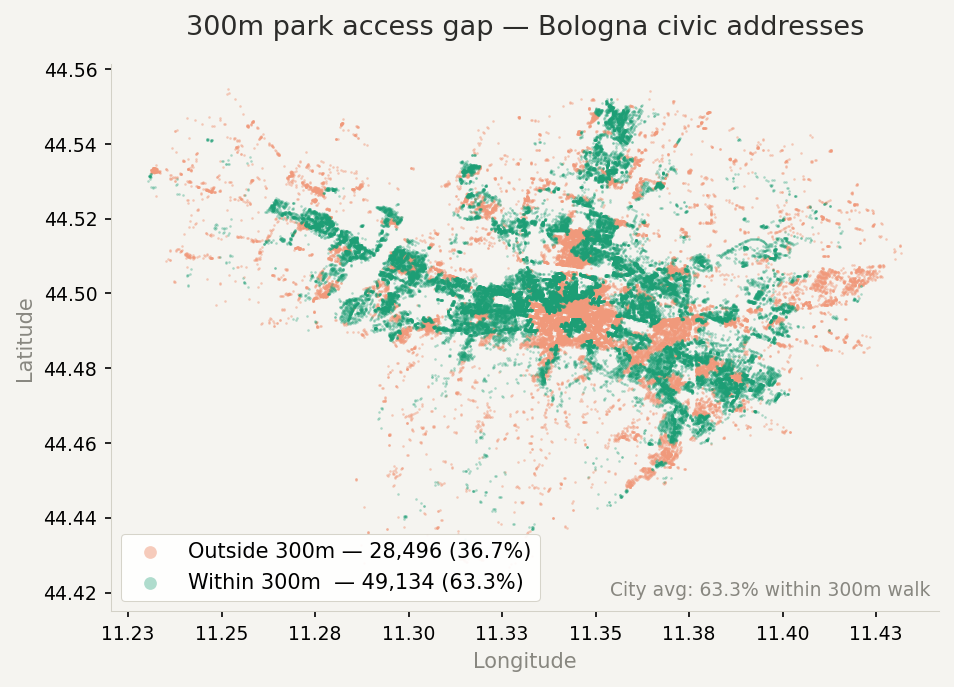

Saved fig4_access_gap_map.png

Done. 77,630 addresses · 49,134 within 300m · city avg 63.3%


In [29]:
# ── Fig 4 · Access gap map — address scatter coloured by 300m compliance ─────
#
# Each dot = one civic address, plotted at its lon/lat.
# Teal  = within 300m walk of a park
# Coral = outside 300m (the access gap)
# Outside dots are drawn first so inside dots render on top where they overlap.
 
inside  = df[df["within_300m"]]
outside = df[~df["within_300m"]]
 
# Compute a sensible aspect ratio from the data extent
lon_range = df["longitude"].max() - df["longitude"].min()
lat_range = df["latitude"].max()  - df["latitude"].min()
lat_mid   = df["latitude"].mean()
aspect    = lon_range / (lat_range * np.cos(np.radians(lat_mid)))  # degrees correction
fig_w, fig_h = 10, 10 / aspect
 
fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.patch.set_facecolor("#F5F4F0")
ax.set_facecolor("#F5F4F0")
 
ax.scatter(
    outside["longitude"], outside["latitude"],
    s=1.5, color=CORAL, alpha=0.5, linewidths=0,
    label=f"Outside 300m — {len(outside):,} ({len(outside)/TOTAL*100:.1f}%)",
    rasterized=True, zorder=2,
)
ax.scatter(
    inside["longitude"], inside["latitude"],
    s=1.5, color=TEAL, alpha=0.35, linewidths=0,
    label=f"Within 300m  — {len(inside):,} ({len(inside)/TOTAL*100:.1f}%)",
    rasterized=True, zorder=3,
)
 
ax.set_aspect("equal")
ax.set_xlabel("Longitude", fontsize=10, color=SGRAY)
ax.set_ylabel("Latitude",  fontsize=10, color=SGRAY)
ax.set_title("300m park access gap — Bologna civic addresses",
             fontsize=13, fontweight="500", pad=14, color=TEXT)
ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.tick_params(labelsize=9)
for spine in ax.spines.values():
    spine.set_edgecolor(LGRAY)
    spine.set_linewidth(0.5)
 
legend = ax.legend(
    fontsize=10, frameon=True, framealpha=0.92,
    edgecolor=LGRAY, loc="lower left", markerscale=5,
)
legend.get_frame().set_linewidth(0.5)
 
ax.text(0.99, 0.02, f"City avg: {CITY_AVG:.1f}% within 300m walk",
        transform=ax.transAxes, fontsize=9, color=SGRAY, ha="right", va="bottom")
 
plt.tight_layout()
plt.show()
plt.savefig("fig4_access_gap_map.png", dpi=200)
plt.close()
print("Saved fig4_access_gap_map.png")
 
print(f"\nDone. {TOTAL:,} addresses · {N_WITHIN:,} within 300m · city avg {CITY_AVG:.1f}%")
 